# EXP-009 — Tinh chỉnh Random Forest

**Notebook trình bày và tổng hợp:** [notebooks/experiments/Mai_EXP-009_RF_tuning.ipynb](../../../notebooks/experiments/Mai_EXP-009_RF_tuning.ipynb)

**Người thực hiện:** Mai  
**Ngày thực hiện:** 20/11/2026  
**So sánh train và test** -22/11/2026  
Thí nghiệm khảo sát ảnh hưởng của số cây, độ sâu tối đa và số đặc trưng được xét tại mỗi lần chia nhánh đến khả năng nhận diện stress của Random Forest. Kết quả được so sánh với RF mặc định 100 cây trong EXP-005 trên cùng bộ dữ liệu physiological68 và cách chia LOSO theo người.

Kết quả G4 được sử dụng làm mốc đối chiếu với lượt chạy lại ngày 20/11/2026. Mỗi lượt gồm 15 fold nhị phân và 15 fold ba lớp. Hai lượt được đối chiếu riêng, không gộp thành các quan sát độc lập.


## 02 — Câu hỏi nghiên cứu

Thay đổi `n_estimators`, `max_depth`, `max_features` qua 4 ứng viên G4 có cải thiện
Macro-F1 và Balanced Accuracy ngoài người học so với RF mặc định không?

Giả thuyết: chọn cấu hình bằng inner GroupKFold có thể cải thiện điểm test, nhưng mức tăng
có thể khác giữa binary và multiclass, và giữa các người tham gia. Chỉ thay tham số RF;
giữ dữ liệu physiological68, seed, nhãn, quy trình train-only và không cân bằng lớp.
Vì 4 ứng viên thay nhiều tham số cùng lúc, thí nghiệm này không tách riêng tác động nhân quả của từng tham số.


In [1]:
from pathlib import Path
import hashlib
import json
import subprocess
import sys

import numpy as np
import pandas as pd
import yaml
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

here = Path.cwd()
repo = next(p for p in (here, *here.parents) if (p / 'src/wesad/evaluation.py').is_file())
package = repo / 'experiments/02_tuning/EXP-009_RF'
experiment = repo / 'outputs/exp009_rf_mai_20261120_report'
CONFIG_YAML = "experiment_id: EXP-009\nauthor: Mai\nrun_date: '2026-11-20'\nrun_kind: rerun\nprotocol: exp009_rf_nested_physiological68_v1\nfeatures: data/features/g2_physiological68_group15_20261107/all_subjects.csv\nschema: data/features/g2_physiological68_group15_20261107/feature_schema.json\nfeature_version: physiological_68_v1\nfeature_sha256: 2f2fddd678f333a800f2869d2e78b407934b2c3492190ed70e28d8a9107fd8ba\noutput_dir: outputs/exp009_rf_mai_20261120\nexpected_subjects: [S2, S3, S4, S5, S6, S7, S8, S9, S10, S11, S13, S14, S15, S16, S17]\nmodels: [rf]\ntasks: [multiclass, binary]\nseed: 42\nsensor_set: combined_physiological68\nnormalization: global_train\nbalance: false\nnested: true\ninner_splits: 3\nzero_division: 0\nmissing_train_class: error\nmissing_test_class: fixed_labels_for_macro_f1_observed_classes_for_balanced_accuracy\nmodel_params:\n  rf: {random_state: 42, n_jobs: 1}\nsearch_spaces:\n  rf:\n    - model__n_estimators: [100]\n      model__max_depth: [10]\n      model__max_features: [sqrt]\n    - model__n_estimators: [200]\n      model__max_depth: [null]\n      model__max_features: [sqrt]\n    - model__n_estimators: [100]\n      model__max_depth: [null]\n      model__max_features: [0.5]\n    - model__n_estimators: [200]\n      model__max_depth: [10]\n      model__max_features: [0.5]\nsource_paths:\n  - src/wesad/data.py\n  - src/wesad/evaluation.py\n  - src/wesad/models.py\n  - src/wesad/utils.py\n  - src/wesad/g4.py\n  - scripts/run_exp009_rf.py\nsource_hash_normalization: LF\n"
# Lưu cấu hình thí nghiệm.
experiment.mkdir(parents=True, exist_ok=True)
(experiment / 'config.yaml').write_text(CONFIG_YAML, encoding='utf-8')
config = yaml.safe_load(CONFIG_YAML)
(package / 'config.yaml').write_text(CONFIG_YAML, encoding='utf-8')
metrics = ['macro_f1', 'balanced_accuracy']
tasks = ['binary', 'multiclass']
task_names = {'binary': 'Nhị phân', 'multiclass': 'Ba lớp'}
figures = experiment / 'figures'
figures.mkdir(exist_ok=True)
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 10})
print('Thư mục hồ sơ:', experiment)
print('Môi trường phân tích:', sys.version.split()[0])


Thư mục hồ sơ: D:\mayhoc\Machine-learning\wesad-stress-detection\outputs\exp009_rf_mai_20261120_report
Môi trường phân tích: 3.13.9


## 03 — Dữ liệu

Sử dụng bảng physiological68 đã khóa SHA256, cùng 15 subject như EXP-005.
Binary: 0 = không stress (baseline và amusement), 1 = stress.
Multiclass: 1 = baseline, 2 = stress, 3 = amusement.
Mã người và mã cửa sổ chỉ dùng để chia fold/đối chiếu; không đưa vào 68 biến đầu vào.


In [2]:
data_path = repo / config['features']
schema_path = repo / config['schema']
digest = hashlib.sha256(data_path.read_bytes()).hexdigest()
assert digest == config['feature_sha256'], 'Dữ liệu không còn khớp lượt chạy'
schema = json.loads(schema_path.read_text(encoding='utf-8'))
data = pd.read_csv(data_path, dtype={'subject_id': str, 'window_id': str})
assert len(schema['feature_columns']) == 68
assert set(data.subject_id) == set(config['expected_subjects'])
assert not data.duplicated(['subject_id', 'window_id']).any()
print('CSV:', config['features'])
print('SHA256:', digest)
print('Số dòng:', len(data), '| Số đặc trưng:', len(schema['feature_columns']), '| Số người:', data.subject_id.nunique())
display(data.groupby('subject_id').size().rename('Số cửa sổ').to_frame())
display(data.label_original.value_counts().sort_index().rename('Số cửa sổ theo nhãn').to_frame())


CSV: data/features/g2_physiological68_group15_20261107/all_subjects.csv
SHA256: 2f2fddd678f333a800f2869d2e78b407934b2c3492190ed70e28d8a9107fd8ba
Số dòng: 6189 | Số đặc trưng: 68 | Số người: 15


,Số cửa sổ
subject_id,
S10,426
S11,417
S13,417
S14,410
S15,418
S16,415
S17,426
S2,395
S3,401


,Số cửa sổ theo nhãn
label_original,
1,3370
2,1848
3,971


## 04 — Protocol đánh giá

- Outer LOSO: giữ riêng 1 người test, 14 người train, đủ 15 lượt cho từng bài toán.
- Inner GroupKFold: chia 14 người train thành 3 fold theo người. Chọn ứng viên bằng trung bình Macro-F1 của 3 inner fold.
- Mỗi lần fit dùng median imputation học trên train của fold đó. RF không cần scaling trong pipeline dùng chung.
- Sau lựa chọn, refit trên đủ outer train rồi dự đoán người outer test; outer test không tham gia chọn cấu hình.
- Seed 42; RF và GridSearchCV dùng `n_jobs=1`. Không feature selection, resampling hoặc class weighting.
- Macro-F1 dùng nhãn cố định và `zero_division=0`; Balanced Accuracy dùng các lớp thực sự xuất hiện trong test.
- Báo cáo mean và sample SD (`ddof=1`) theo 15 người. Confusion matrix tổng hợp dự đoán OOF có trọng số theo số cửa sổ, không thay thế mean theo người.

4 ứng viên × 3 inner fold × 30 outer fold = 360 inner fit, cộng 30 outer refit.
Mã huấn luyện dùng `src/wesad/evaluation.py`; notebook không viết lại LOSO.


## 05 — Cấu hình

Baseline EXP-005: `n_estimators=100`, `max_depth=None`, `max_features='sqrt'`, `class_weight=None`.
4 cấu hình dưới giữ nguyên grid G4. C1–C4 chỉ là tên để đọc biểu đồ, không phải thứ hạng.
`max_features=0.5` là xét khoảng một nửa số biến tại mỗi lần chia nhánh; cả 68 biến vẫn được đưa vào RF.


In [3]:
grid = [dict(zip(item.keys(), [v[0] for v in item.values()])) for item in config['search_spaces']['rf']]
candidate_names = {json.dumps(params, sort_keys=True): f'C{i + 1}' for i, params in enumerate(grid)}
display(pd.DataFrame(grid, index=[f'C{i + 1}' for i in range(len(grid))]))
print((experiment / 'config.yaml').read_text(encoding='utf-8'))


experiment_id: EXP-009
author: Mai
run_date: '2026-11-20'
run_kind: rerun
protocol: exp009_rf_nested_physiological68_v1
features: data/features/g2_physiological68_group15_20261107/all_subjects.csv
schema: data/features/g2_physiological68_group15_20261107/feature_schema.json
feature_version: physiological_68_v1
feature_sha256: 2f2fddd678f333a800f2869d2e78b407934b2c3492190ed70e28d8a9107fd8ba
output_dir: outputs/exp009_rf_mai_20261120
expected_subjects: [S2, S3, S4, S5, S6, S7, S8, S9, S10, S11, S13, S14, S15, S16, S17]
models: [rf]
tasks: [multiclass, binary]
seed: 42
sensor_set: combined_physiological68
normalization: global_train
balance: false
nested: true
inner_splits: 3
zero_division: 0
missing_train_class: error
missing_test_class: fixed_labels_for_macro_f1_observed_classes_for_balanced_accuracy
model_params:
  rf: {random_state: 42, n_jobs: 1}
search_spaces:
  rf:
    - model__n_estimators: [100]
      model__max_depth: [10]
      model__max_features: [sqrt]
    - model__n_estimat

,model__n_estimators,model__max_depth,model__max_features
C1,100,10.0,sqrt
C2,200,NaN,sqrt
C3,100,NaN,0.5
C4,200,10.0,0.5


## 06 — Huấn luyện và tổng hợp kết quả

Quá trình huấn luyện sử dụng runner dùng chung với cấu hình đã xác định ở phần 05. Biến `RUN_TRAIN` điều khiển việc thực hiện huấn luyện; giá trị `False` giữ chế độ đọc kết quả đã lưu, còn `True` thực hiện chạy hoặc tiếp tục các fold chưa hoàn thành. Các fold chỉ được sử dụng lại khi chữ ký và checksum còn hợp lệ.

Checkpoint huấn luyện được lưu tại `outputs/exp009_rf_mai_20261120/`. Bảng phân tích chi tiết được lưu tại `outputs/exp009_rf_mai_20261120_report/`. Hồ sơ EXP-009 giữ cấu hình, bảng kết quả, bảng so sánh EXP-005 và thư mục hình, theo cách tổ chức của EXP-005. Script tổng hợp tạo bảng điểm, dự đoán và các bảng đối chiếu phục vụ phân tích. Môi trường huấn luyện sử dụng Python 3.12.14 trong `.venv-g1`.


In [ ]:
RUN_TRAIN = False
train_python = repo / '.venv-g1/Scripts/python.exe'
train_command = [str(train_python), '-X', 'utf8', 'scripts/run_exp009_rf.py', '--config',
                 str(experiment / 'config.yaml'), '--resume']
report_command = [str(train_python), '-X', 'utf8', 'scripts/report_exp009_rf.py', '--destination', str(experiment)]
print('Lệnh chạy:', subprocess.list2cmdline(train_command))
if RUN_TRAIN:
    subprocess.run(train_command, cwd=repo, check=True)
    subprocess.run(report_command, cwd=repo, check=True)
else:
    print('Chỉ đọc kết quả đã lưu; không fit mô hình trong lần mở notebook này.')


# Lưu hồ sơ gọn theo cách tổ chức của EXP-005.
import shutil
for source_name, output_name in [('results.csv', 'results.csv'), ('comparison_exp005.csv', 'comparison_baseline.csv')]:
    source = experiment / source_name
    if source.exists():
        shutil.copy2(source, package / output_name)


## 07 — Kết quả và kiểm tra bằng chứng

`results.csv` là lượt chạy lại ngày 20/11. `results_historical.csv` là nguồn G4 đã kiểm chứng
từ 2 gói RF/MLP được ghép đủ 15 người; chỉ lấy RF. `results_baseline.csv` là EXP-005 đã xác minh.
Các bảng được ghép theo task và subject, không ghép theo thứ tự dòng.

Kết quả hiển thị bên dưới lấy từ hồ sơ đã chạy ngày 20/11/2026 và hình đã lưu của lượt này. Đã kiểm tra đủ 30 fold và checksum các tệp trong từng fold. Không chạy lại huấn luyện khi bổ sung kết quả.


In [4]:
proof = json.loads((experiment / 'verification.json').read_text(encoding='utf-8'))
provenance = json.loads((experiment / 'provenance.json').read_text(encoding='utf-8'))
assert proof['status'] == 'passed' and proof['n_folds'] == 30
assert proof['n_predictions'] == len(data) * 2
assert proof['producer']['data_sha256'] == digest
results = pd.read_csv(experiment / 'results.csv')
predictions = pd.read_csv(experiment / 'predictions.csv', dtype={'subject_id': str, 'window_id': str})
summary = pd.read_csv(experiment / 'comparison_summary.csv')
paired = pd.read_csv(experiment / 'comparison_exp005.csv')
history_comparison = pd.read_csv(experiment / 'comparison_historical.csv')
assert len(results) == len(paired) == len(history_comparison) == 30
assert not results.duplicated(['task', 'subject_id']).any()
assert not predictions.duplicated(['task', 'subject_id', 'window_id']).any()
assert all(set(g.subject_id) == set(config['expected_subjects']) for _, g in results.groupby('task'))
# Verify all saved fold files against their signed completion manifest.
for task in config['tasks']:
    for subject in config['expected_subjects']:
        folder = experiment / 'folds' / task / 'rf' / subject
        done = json.loads((folder / 'complete.json').read_text(encoding='utf-8'))
        assert done['signature'] == proof['producer']['signature']
        for name, expected_hash in done['files'].items():
            assert hashlib.sha256((folder / name).read_bytes()).hexdigest() == expected_hash
display(summary.round(4))
display(results[['task', 'subject_id'] + metrics].round(4))
display(Markdown('**Mean ± SD theo người**'))
for row in summary.itertuples():
    print(f'{row.variant}, {row.task}: Macro-F1 {row.macro_f1_mean:.4f} ± {row.macro_f1_std:.4f}; '
          f'BA {row.balanced_accuracy_mean:.4f} ± {row.balanced_accuracy_std:.4f}')
print('Đối chiếu G4 lịch sử:', provenance['historical_comparison'])


baseline_EXP005, binary: Macro-F1 0.8735 ± 0.1440; BA 0.8865 ± 0.1143
baseline_EXP005, multiclass: Macro-F1 0.6480 ± 0.1297; BA 0.6700 ± 0.1204
historical_G4, binary: Macro-F1 0.8655 ± 0.1412; BA 0.8782 ± 0.1141
historical_G4, multiclass: Macro-F1 0.6540 ± 0.1388; BA 0.6731 ± 0.1348
rerun_EXP009, binary: Macro-F1 0.8655 ± 0.1412; BA 0.8782 ± 0.1141
rerun_EXP009, multiclass: Macro-F1 0.6540 ± 0.1388; BA 0.6731 ± 0.1348
Đối chiếu G4 lịch sử: {'n_folds': 30, 'max_abs_metric_difference': 0.0, 'n_changed_metric_folds': 0, 'n_changed_parameter_folds': 0}


,variant,task,n_subjects,macro_f1_mean,macro_f1_std,balanced_accuracy_mean,balanced_accuracy_std,fit_and_search_seconds_mean
0,baseline_EXP005,binary,15,0.8735,0.1440,0.8865,0.1143,2.2125
1,baseline_EXP005,multiclass,15,0.6480,0.1297,0.6700,0.1204,2.8055
2,historical_G4,binary,15,0.8655,0.1412,0.8782,0.1141,81.8050
3,historical_G4,multiclass,15,0.6540,0.1388,0.6731,0.1348,66.8738
4,rerun_EXP009,binary,15,0.8655,0.1412,0.8782,0.1141,95.5722
5,rerun_EXP009,multiclass,15,0.6540,0.1388,0.6731,0.1348,99.0711


,task,subject_id,macro_f1,balanced_accuracy
0,multiclass,S10,0.4427,0.4493
1,multiclass,S11,0.8472,0.8281
2,multiclass,S13,0.4995,0.5752
3,multiclass,S14,0.4870,0.4606
4,multiclass,S15,0.8293,0.8408
5,multiclass,S16,0.8132,0.7872
6,multiclass,S17,0.5209,0.5481
7,multiclass,S2,0.6052,0.6171
8,multiclass,S3,0.6788,0.6775
9,multiclass,S4,0.6241,0.6667


**Mean ± SD theo người**

## 08 — Hình minh họa

Hình lấy trực tiếp từ CSV của EXP-005 và lượt chạy lại EXP-009.
Thanh sai số là SD giữa người, không phải khoảng tin cậy.


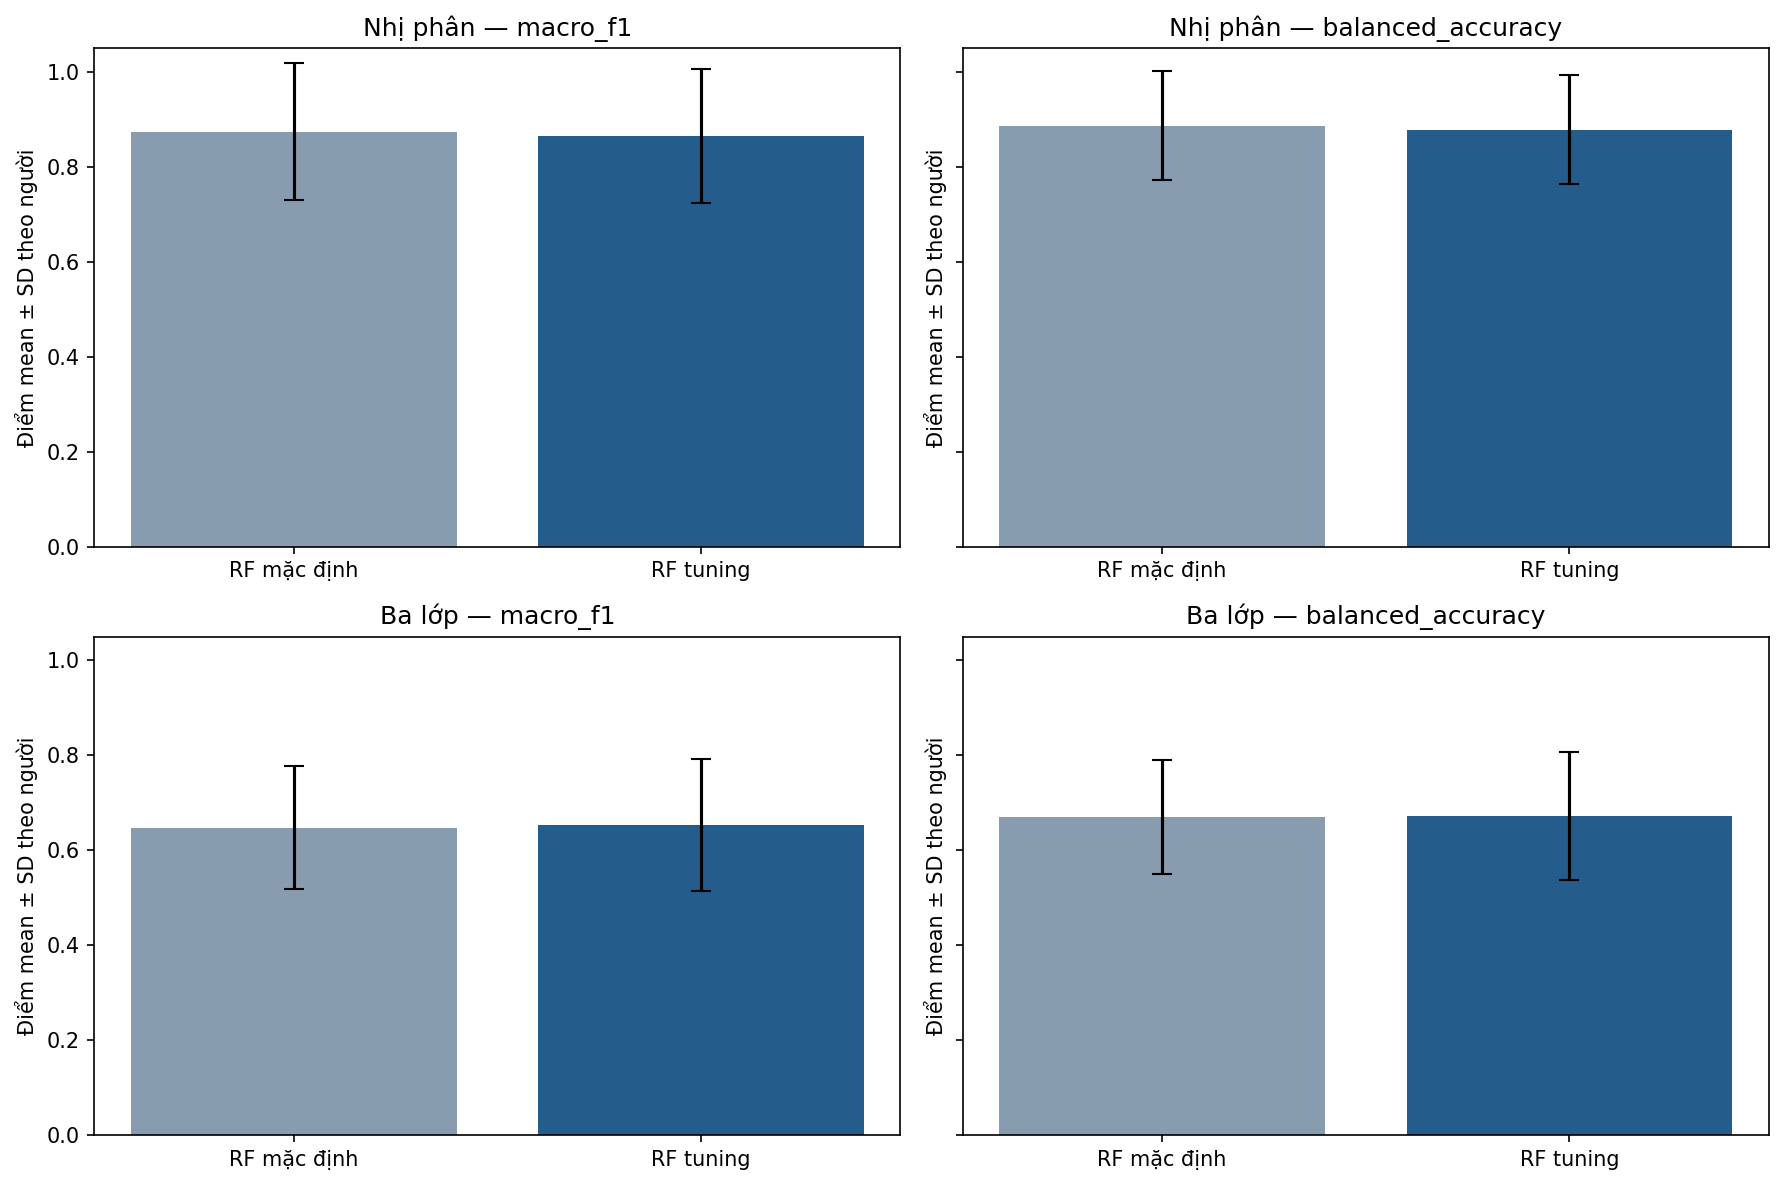

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharey=True)
for i, task in enumerate(tasks):
    for j, metric in enumerate(metrics):
        part = summary.loc[summary.task.eq(task)].set_index('variant').loc[['baseline_EXP005', 'rerun_EXP009']]
        ax = axes[i, j]
        ax.bar(['RF mặc định', 'RF tuning'], part[metric + '_mean'], yerr=part[metric + '_std'],
               color=['#879CAF', '#245C8C'], capsize=5)
        ax.set_title(f'{task_names[task]} — {metric}')
        ax.set_ylim(0, 1.05); ax.set_ylabel('Điểm mean ± SD theo người')
fig.tight_layout()
fig.savefig(figures / 'default_vs_tuned.png', dpi=150, bbox_inches='tight')
plt.show()


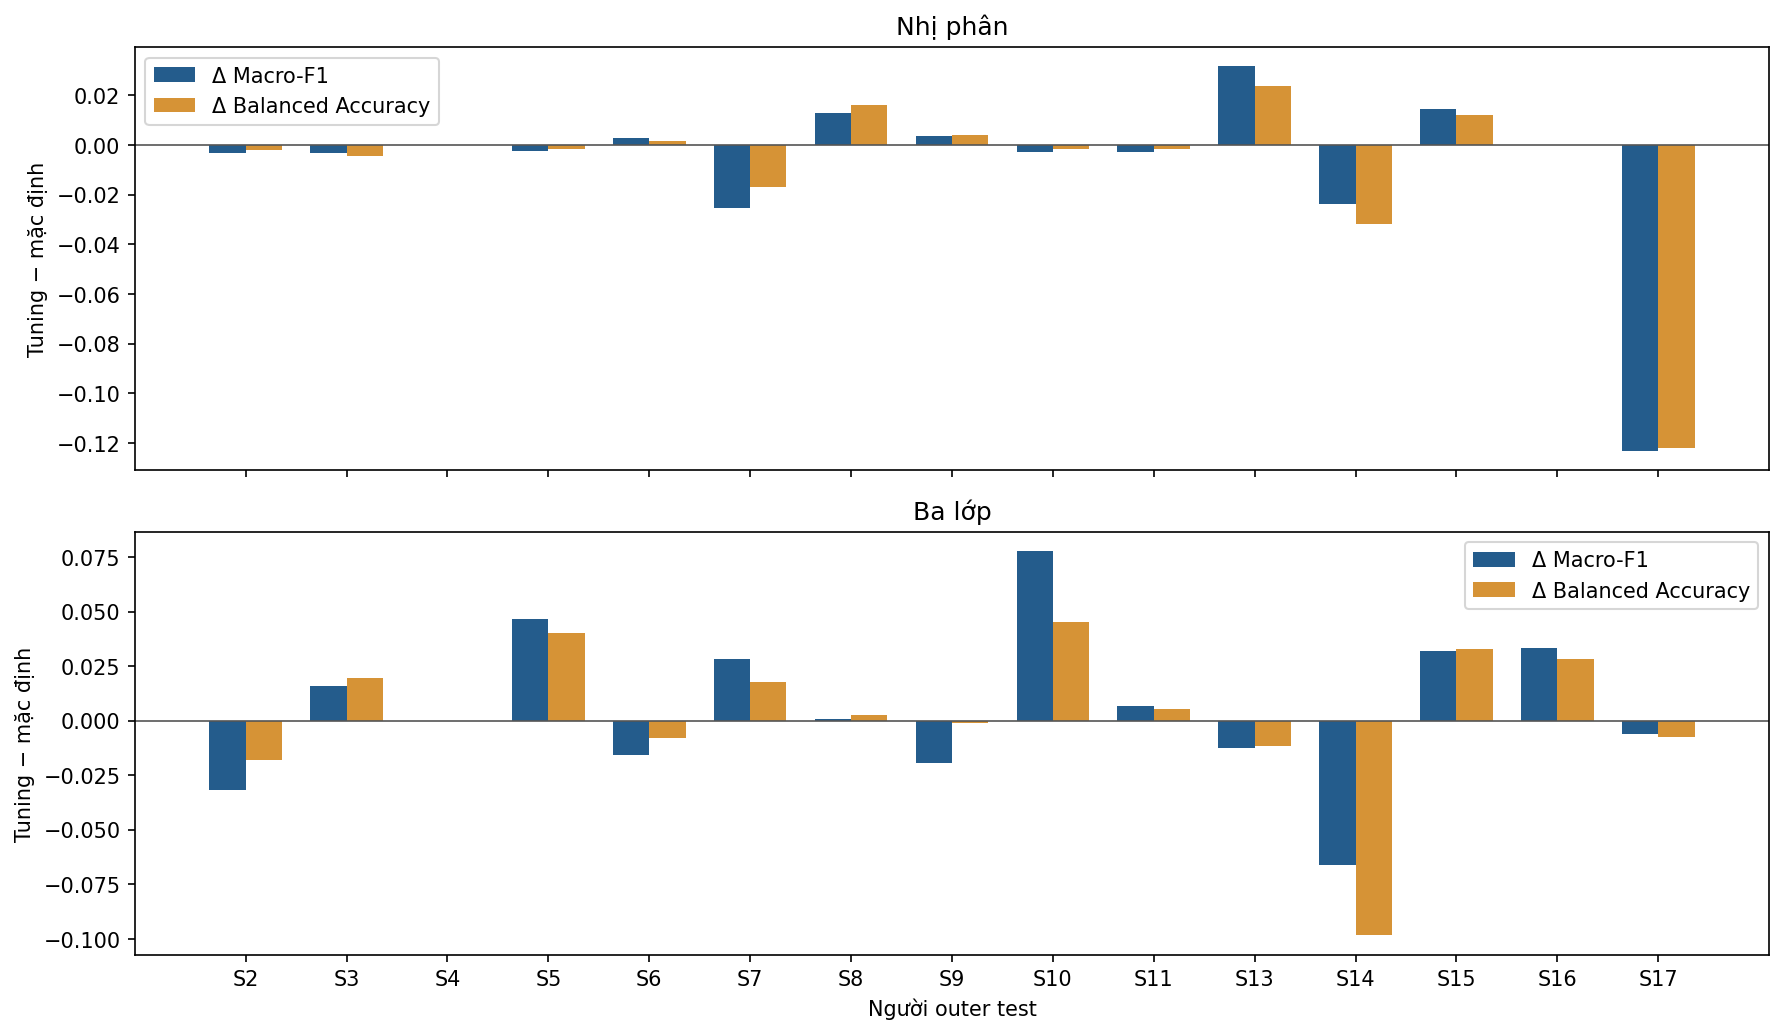

In [ ]:
order = config['expected_subjects']
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
for ax, task in zip(axes, tasks):
    part = paired.loc[paired.task.eq(task)].set_index('subject_id').loc[order]
    x = np.arange(len(order))
    ax.bar(x - .18, part.macro_f1_delta, .36, label='Δ Macro-F1', color='#245C8C')
    ax.bar(x + .18, part.balanced_accuracy_delta, .36, label='Δ Balanced Accuracy', color='#D69336')
    ax.axhline(0, color='#555555', linewidth=.8)
    ax.set_title(task_names[task]); ax.set_ylabel('Tuning − mặc định'); ax.legend()
axes[-1].set_xticks(np.arange(len(order)), order); axes[-1].set_xlabel('Người outer test')
fig.tight_layout(); fig.savefig(figures / 'delta_by_subject.png', dpi=150, bbox_inches='tight')
plt.show()


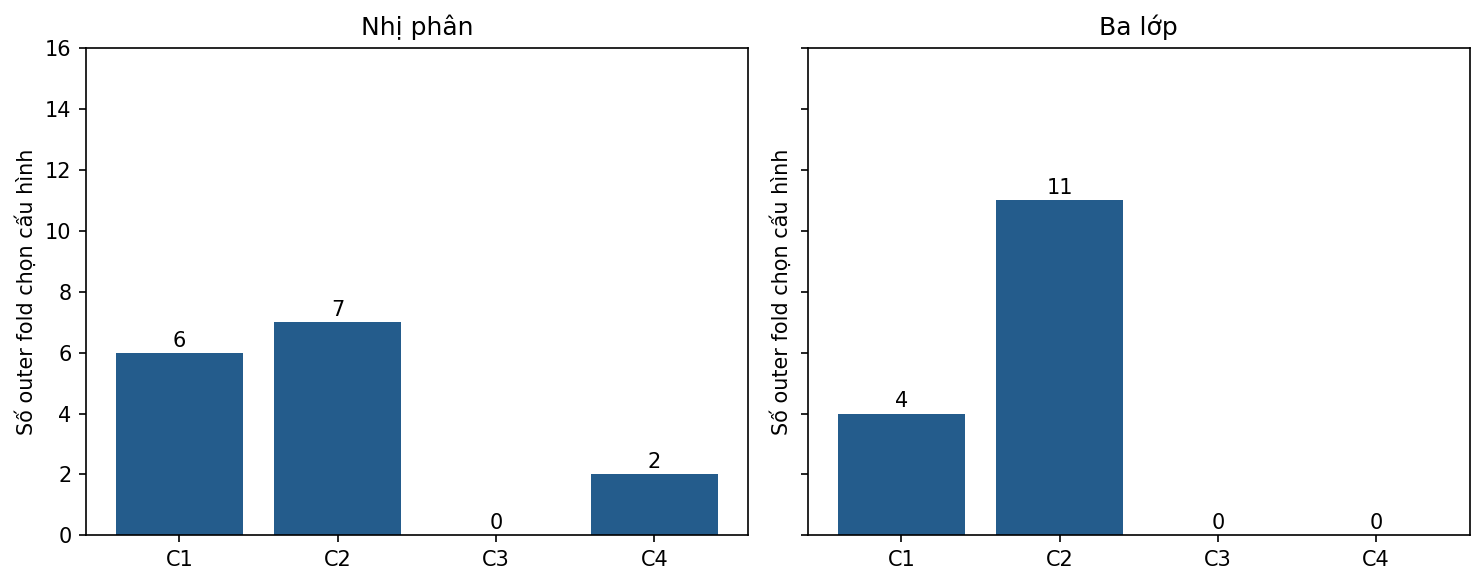

task,subject_id,model__max_depth,model__max_features,model__n_estimators,configuration
multiclass,S2,NaN,sqrt,200,"{""model__max_depth"": null, ""model__max_features"": ""sqrt"", ""model__n_estimators"": 200}"
multiclass,S3,10.0,sqrt,100,"{""model__max_depth"": 10, ""model__max_features"": ""sqrt"", ""model__n_estimators"": 100}"
multiclass,S4,NaN,sqrt,200,"{""model__max_depth"": null, ""model__max_features"": ""sqrt"", ""model__n_estimators"": 200}"
multiclass,S5,NaN,sqrt,200,"{""model__max_depth"": null, ""model__max_features"": ""sqrt"", ""model__n_estimators"": 200}"
multiclass,S6,10.0,sqrt,100,"{""model__max_depth"": 10, ""model__max_features"": ""sqrt"", ""model__n_estimators"": 100}"
multiclass,S7,10.0,sqrt,100,"{""model__max_depth"": 10, ""model__max_features"": ""sqrt"", ""model__n_estimators"": 100}"
multiclass,S8,NaN,sqrt,200,"{""model__max_depth"": null, ""model__max_features"": ""sqrt"", ""model__n_estimators"": 200}"
multiclass,S9,NaN,sqrt,200,"{""model__max_depth"": null, ""model__max_features"": ""sqrt"", ""model__n_estimators"": 200}"
multiclass,S10,NaN,sqrt,200,"{""model__max_depth"": null, ""model__max_features"": ""sqrt"", ""model__n_estimators"": 200}"
multiclass,S11,NaN,sqrt,200,"{""model__max_depth"": null, ""model__max_features"": ""sqrt"", ""model__n_estimators"": 200}"


In [ ]:
frequency = pd.read_csv(experiment / 'candidate_frequency.csv')
frequency['candidate'] = frequency.configuration.map(candidate_names)
assert frequency.candidate.notna().all()
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, task in zip(axes, tasks):
    values = frequency.loc[frequency.task.eq(task)].set_index('candidate').n_subjects.reindex(['C1', 'C2', 'C3', 'C4'], fill_value=0)
    assert values.sum() == 15
    ax.bar(values.index, values, color='#245C8C')
    ax.set_title(task_names[task]); ax.set_ylim(0, 16); ax.set_ylabel('Số outer fold chọn cấu hình')
    for i, v in enumerate(values): ax.text(i, v + .2, str(v), ha='center')
fig.tight_layout(); fig.savefig(figures / 'candidate_frequency.png', dpi=150, bbox_inches='tight')
plt.show()
display(pd.read_csv(experiment / 'best_params_by_subject.csv'))


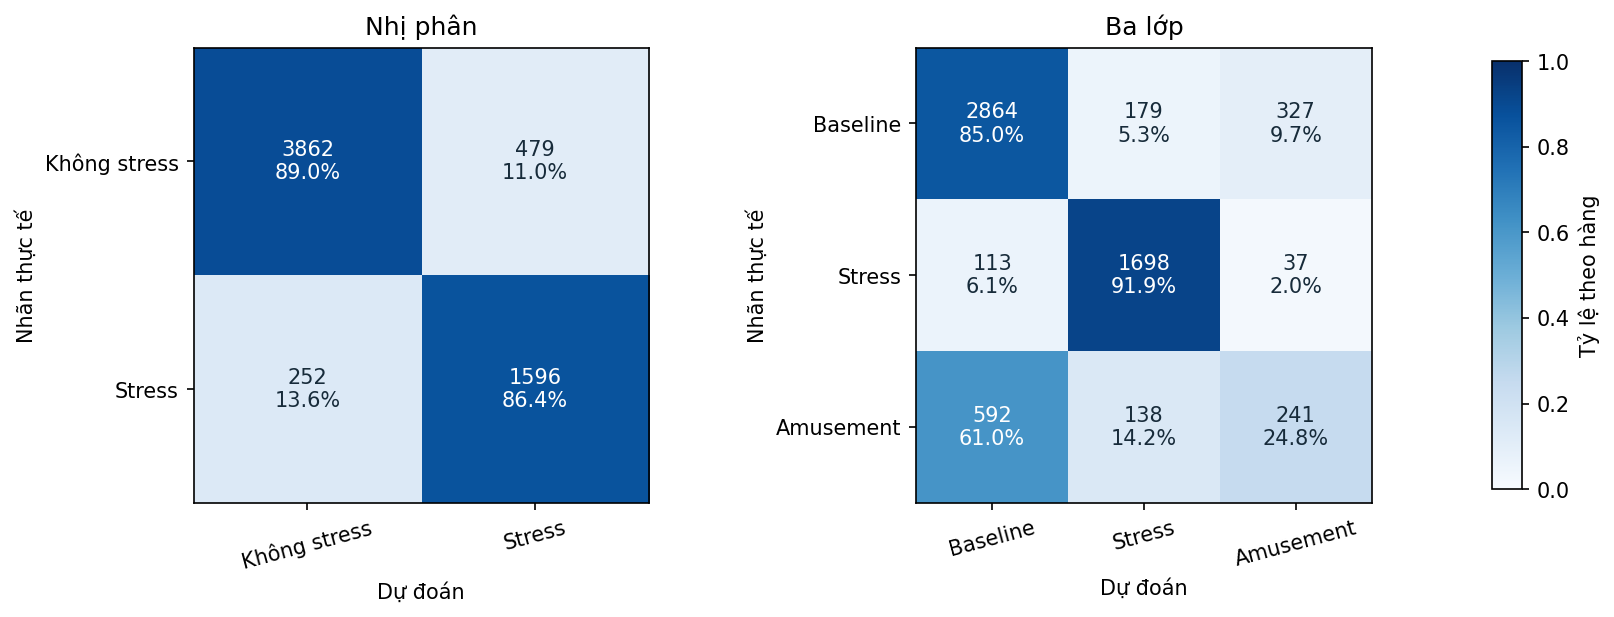

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
for ax, task in zip(axes, tasks):
    saved = json.loads((experiment / f'confusion_matrix_{task}.json').read_text(encoding='utf-8'))
    matrix = np.asarray(saved['matrix'])
    normalized = matrix / matrix.sum(axis=1, keepdims=True)
    labels = ['Không stress', 'Stress'] if task == 'binary' else ['Baseline', 'Stress', 'Amusement']
    im = ax.imshow(normalized, cmap='Blues', vmin=0, vmax=1)
    for i in range(len(labels)):
        for j in range(len(labels)):
            ax.text(j, i, f'{matrix[i,j]}\n{normalized[i,j]:.1%}', ha='center', va='center',
                    color='white' if normalized[i,j] > .55 else '#172B3A')
    ax.set_xticks(range(len(labels)), labels, rotation=15)
    ax.set_yticks(range(len(labels)), labels)
    ax.set_xlabel('Dự đoán'); ax.set_ylabel('Nhãn thực tế'); ax.set_title(task_names[task])
fig.subplots_adjust(left=.10, right=.84, bottom=.20, top=.86, wspace=.45)
cax = fig.add_axes([.90, .22, .018, .62])
fig.colorbar(im, cax=cax, label='Tỷ lệ theo hàng')
fig.savefig(figures / 'confusion_matrices.png', dpi=150, bbox_inches='tight')
plt.show()


## 09 — Phân tích

Đánh giá đồng thời điểm trung bình, biến thiên theo người, số người được cải thiện và lỗi theo lớp.
Recall bên dưới được tính trên OOF gộp mọi cửa sổ; mỗi người có thể đóng góp số cửa sổ khác nhau.
Thời gian tìm kiếm/fit không phải độ trễ suy luận, và chỉ mô tả tài nguyên của lượt chạy này.


In [5]:
lines = []
for task in tasks:
    part = paired.loc[paired.task.eq(task)]
    tuned = results.loc[results.task.eq(task)]
    weak = tuned.nsmallest(2, 'macro_f1')
    df1, dba = part.macro_f1_delta.mean(), part.balanced_accuracy_delta.mean()
    wins = int(part.macro_f1_delta.gt(1e-10).sum())
    losses = int(part.macro_f1_delta.lt(-1e-10).sum())
    ties = len(part) - wins - losses
    worst = part.loc[part.macro_f1_delta.idxmin()]
    best_row = part.loc[part.macro_f1_delta.idxmax()]
    score = tuned.macro_f1.mean()
    lines.append(f"### {task_names[task]}\n"
        f"RF tuning đạt Macro-F1 {score:.4f} ± {tuned.macro_f1.std(ddof=1):.4f}. "
        f"So với EXP-005, ΔMacro-F1 {df1:+.4f}, ΔBA {dba:+.4f}. "
        f"Macro-F1 tăng ở {wins}/15 người, giảm ở {losses}/15 và không đổi ở {ties}/15. "
        f"Mức tăng lớn nhất ở {best_row.subject_id} ({best_row.macro_f1_delta:+.4f}); "
        f"thay đổi thấp nhất ở {worst.subject_id} ({worst.macro_f1_delta:+.4f}). "
        f"Hai fold có điểm tuning thấp nhất: " + ', '.join(f'{r.subject_id} ({r.macro_f1:.4f})' for r in weak.itertuples()) + '.')
display(Markdown('\n\n'.join(lines)))
display(pd.read_csv(experiment / 'classification_report.csv').round(4))
display(summary[['variant', 'task', 'fit_and_search_seconds_mean']].round(2))
display(Markdown('Không thể quy mọi thay đổi cho một tham số riêng vì grid đồng thời thay số cây, độ sâu và số biến xét tại mỗi lần chia. Các chênh lệch là kết quả quan sát, chưa có kiểm định ý nghĩa thống kê.'))


### Nhị phân
RF tuning đạt Macro-F1 0.8655 ± 0.1412. So với EXP-005, ΔMacro-F1 -0.0080, ΔBA -0.0083. Macro-F1 tăng ở 5/15 người, giảm ở 8/15 và không đổi ở 2/15. Mức tăng lớn nhất ở S13 (+0.0317); thay đổi thấp nhất ở S17 (-0.1232). Hai fold có điểm tuning thấp nhất: S10 (0.4990), S15 (0.7003).

### Ba lớp
RF tuning đạt Macro-F1 0.6540 ± 0.1388. So với EXP-005, ΔMacro-F1 +0.0060, ΔBA +0.0031. Macro-F1 tăng ở 8/15 người, giảm ở 6/15 và không đổi ở 1/15. Mức tăng lớn nhất ở S10 (+0.0778); thay đổi thấp nhất ở S14 (-0.0662). Hai fold có điểm tuning thấp nhất: S10 (0.4427), S14 (0.4870).

,task,label,precision,recall,f1-score,support
0,multiclass,1,0.8025,0.8499,0.8255,3370.0
1,multiclass,2,0.8427,0.9188,0.8791,1848.0
2,multiclass,3,0.3983,0.2482,0.3058,971.0
3,binary,0,0.9387,0.8897,0.9135,4341.0
4,binary,1,0.7692,0.8636,0.8137,1848.0


,variant,task,fit_and_search_seconds_mean
0,baseline_EXP005,binary,2.21
1,baseline_EXP005,multiclass,2.81
2,historical_G4,binary,81.81
3,historical_G4,multiclass,66.87
4,rerun_EXP009,binary,95.57
5,rerun_EXP009,multiclass,99.07


Không thể quy mọi thay đổi cho một tham số riêng vì grid đồng thời thay số cây, độ sâu và số biến xét tại mỗi lần chia. Các chênh lệch là kết quả quan sát, chưa có kiểm định ý nghĩa thống kê.

## 10 — Kết luận và nguồn kết quả

Mức cải thiện được đánh giá riêng cho bài toán nhị phân và ba lớp, dựa trên chênh lệch điểm trung bình và biến thiên giữa người tham gia. Cấu hình được chọn có thể khác nhau giữa các outer fold vì quá trình lựa chọn chỉ sử dụng dữ liệu huấn luyện bên trong mỗi fold.

Thí nghiệm đánh giá hiệu quả của quy trình tinh chỉnh tham số. Việc lựa chọn và huấn luyện mô hình triển khai được thực hiện ở bước tổng hợp các thí nghiệm. Thông tin môi trường, cấu hình và mã nguồn được lưu để đối chiếu nguồn kết quả.


In [6]:
conclusions = []
for task in tasks:
    part = paired.loc[paired.task.eq(task)]
    delta = part.macro_f1_delta.mean()
    direction = 'tăng' if delta > 1e-10 else 'giảm' if delta < -1e-10 else 'không đổi'
    conclusions.append(f"- **{task_names[task]}:** Macro-F1 trung bình {direction} ({delta:+.4f}); "
                       f"Balanced Accuracy thay đổi {part.balanced_accuracy_delta.mean():+.4f}. "
                       'Cần cân nhắc cả biến thiên theo người và chi phí tìm kiếm khi chọn mô hình cuối.')
display(Markdown('\n'.join(conclusions)))
history_info = provenance['historical_comparison']
print('Số fold khác điểm so với G4 lịch sử:', history_info['n_changed_metric_folds'])
print('Chênh lệch metric tuyệt đối lớn nhất:', history_info['max_abs_metric_difference'])
print('Số fold khác tham số:', history_info['n_changed_parameter_folds'])
print('Nguồn train mới:', provenance['training_source'])
print('Nguồn baseline:', provenance['baseline_source'])
print('Git commit train:', proof['producer'].get('git_commit'))
print('Commit None: không truy xuất được metadata Git trong môi trường chạy.')
display(proof['producer']['environment'])
print('Chữ ký lượt train:', proof['producer']['signature'])
print('Mã nguồn train đã lưu trong source_snapshot.zip; checksum từng fold trong complete.json.')
print('Nguồn lịch sử và môi trường gốc: historical_provenance.json.')
print('Lần thực thi notebook này chỉ đọc báo cáo và tạo hình khi RUN_TRAIN=False.')


# Lưu hình trong hồ sơ thí nghiệm; checkpoint và bảng kiểm chứng ở outputs/.
shutil.copytree(figures, package / 'figures', dirs_exist_ok=True)


Số fold khác điểm so với G4 lịch sử: 0
Chênh lệch metric tuyệt đối lớn nhất: 0.0
Số fold khác tham số: 0
Nguồn train mới: outputs/exp009_rf_mai_20261120
Nguồn baseline: outputs\exp005_rf_full
Git commit train: None
Commit None: không truy xuất được metadata Git trong môi trường chạy.
Chữ ký lượt train: 04243de935526cc11bbffda70a1af6ee0ba6d565c9f91b57592e10b17937d801
Mã nguồn train đã lưu trong source_snapshot.zip; checksum từng fold trong complete.json.
Nguồn lịch sử và môi trường gốc: historical_provenance.json.
Lần thực thi notebook này chỉ đọc báo cáo và tạo hình khi RUN_TRAIN=False.


- **Nhị phân:** Macro-F1 trung bình giảm (-0.0080); Balanced Accuracy thay đổi -0.0083. Cần cân nhắc cả biến thiên theo người và chi phí tìm kiếm khi chọn mô hình cuối.
- **Ba lớp:** Macro-F1 trung bình tăng (+0.0060); Balanced Accuracy thay đổi +0.0031. Cần cân nhắc cả biến thiên theo người và chi phí tìm kiếm khi chọn mô hình cuối.

{'python': '3.12.14 (main, Sep 29 2026, 15:00:58) [MSC v.1944 64 bit (AMD64)]', 'packages': {'numpy': '2.5.4', 'pandas': '3.1.0', 'PyYAML': '6.0.3', 'scipy': '1.18.1', 'scikit-learn': '1.9.1', 'imbalanced-learn': '0.14.2'}}

## 11 — So sánh train và test của mô hình tuning -22/11/2026

Mỗi outer fold dùng tham số đã chọn từ inner CV của lượt chạy ngày 20/11/2026. Mô hình được fit lại trên 14 người train để bổ sung điểm train, không thực hiện lại tìm kiếm tham số. Đã đối chiếu theo người và mã cửa sổ: **12.378/12.378 dự đoán test khớp kết quả cũ ở đủ 30 fold**.

Điểm train được tính bổ sung, không phải điểm đã lưu từ lần chạy cũ. Cả train và test trong mỗi fold được tính từ cùng một mô hình fit lại. Giá trị thiếu chỉ được điền bằng trung vị học từ train. Thanh sai số là SD qua 15 fold, không phải khoảng tin cậy. Điểm train là điểm trên dữ liệu đã học, không phải điểm inner validation.

Giữ `RECOMPUTE_TRAIN_TEST=False` để đọc kết quả đã lưu. Chỉ bật `True` khi cần tính lại 30 mô hình theo tham số cũ.


train_macro_f1         test_macro_f1         gap_macro_f1         train_balanced_accuracy         test_balanced_accuracy         gap_balanced_accuracy        
                     mean     std          mean     std         mean     std                    mean     std                   mean     std                  mean     std
task                                                                                                                                                                     
binary                1.0  0.0000        0.8655  0.1412       0.1345  0.1412                     1.0  0.0000                 0.8782  0.1141                0.1218  0.1141
multiclass            1.0  0.0001        0.6540  0.1388       0.3460  0.1387                     1.0  0.0001                 0.6731  0.1348                0.3268  0.1348

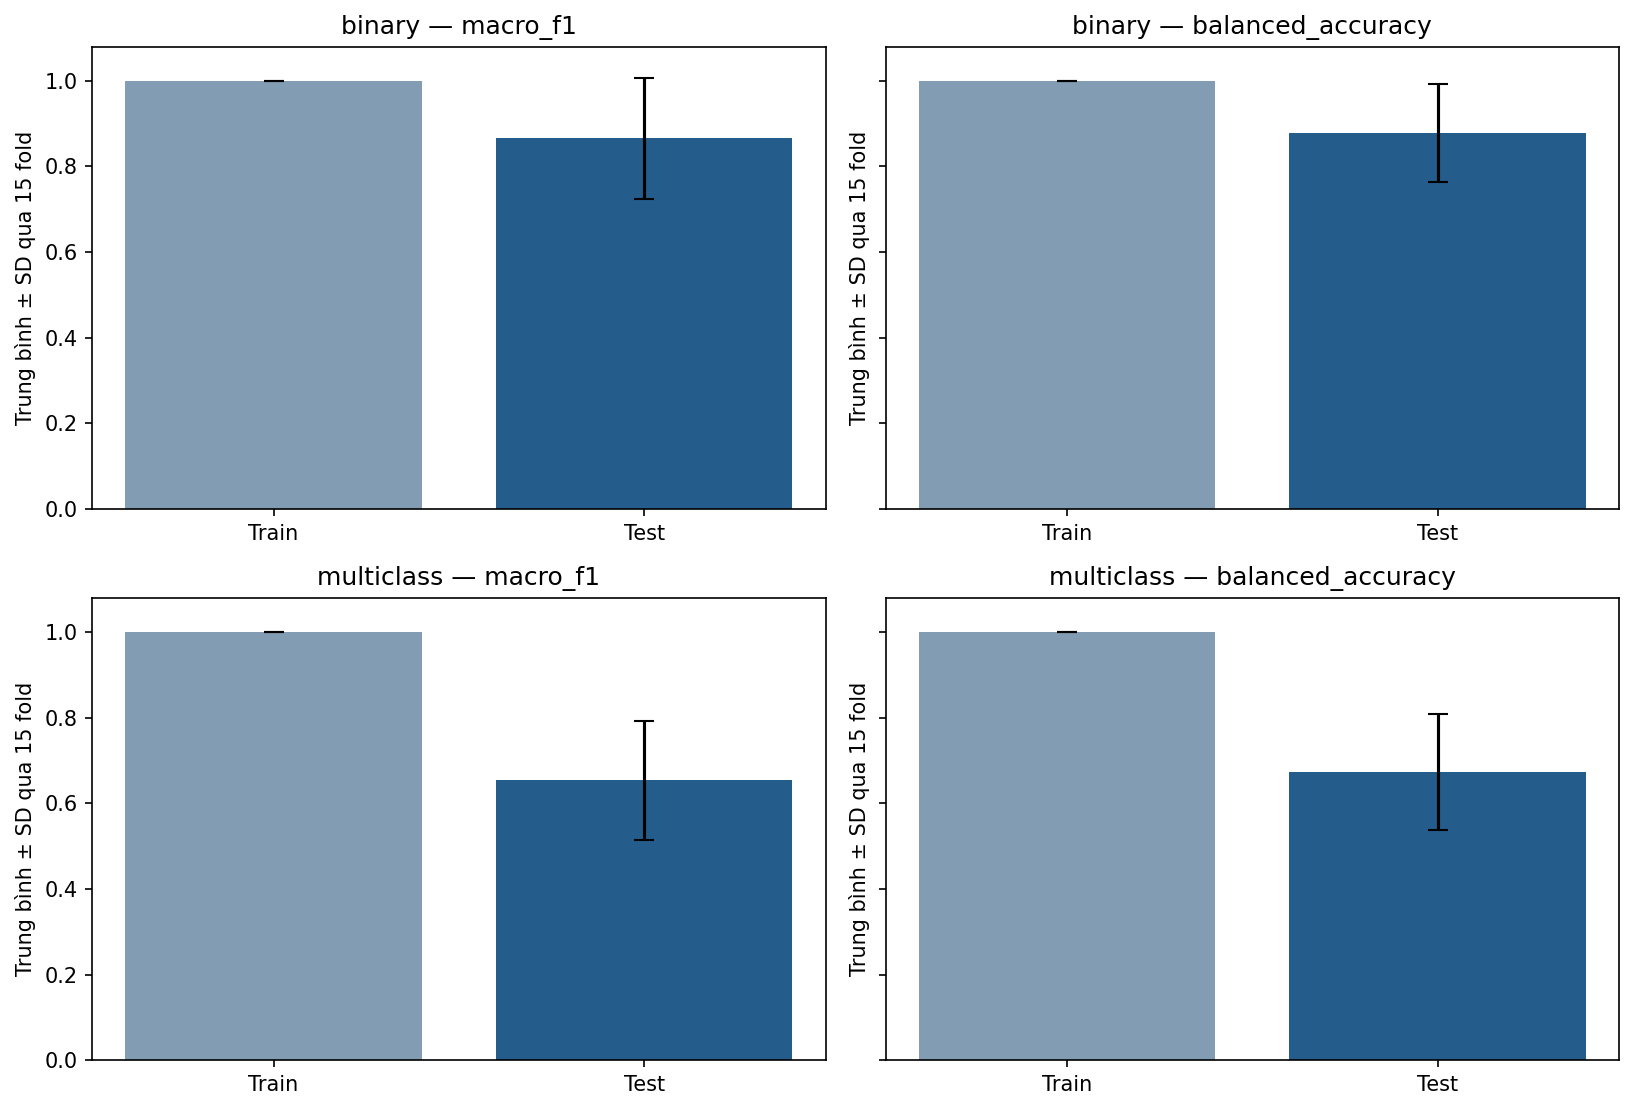

In [7]:
from pathlib import Path
import json, subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
here_tt = Path.cwd()
repo_tt = next(p for p in (here_tt, *here_tt.parents) if (p / 'src/wesad/evaluation.py').is_file())
package_tt = repo_tt / 'experiments/02_tuning/EXP-009_RF'
RECOMPUTE_TRAIN_TEST = False
if RECOMPUTE_TRAIN_TEST:
    subprocess.run([str(repo_tt / '.venv-g1/Scripts/python.exe'), '-X', 'utf8', str(package_tt / 'measure_train_test.py')], cwd=repo_tt, check=True)
check_tt = json.loads((package_tt / 'train_test_verification.json').read_text(encoding='utf-8'))
assert check_tt['status'] == 'passed' and check_tt['n_folds'] == 30
assert check_tt['matched_test_predictions'] == 12378
scores_tt = pd.read_csv(package_tt / 'train_test_selected_folds.csv')
assert len(scores_tt) == 30 and not scores_tt.duplicated(['task', 'subject_id']).any()
original_tt = pd.read_csv(package_tt / 'results.csv')
paired_tt = scores_tt.merge(original_tt, on=['task', 'subject_id'], validate='one_to_one')
assert len(paired_tt) == 30
for metric in ['macro_f1', 'balanced_accuracy']:
    assert np.allclose(paired_tt[f'test_{metric}'], paired_tt[metric], atol=1e-12, rtol=0)
columns_tt = [f'{split}_{metric}' for metric in ['macro_f1', 'balanced_accuracy'] for split in ['train', 'test', 'gap']]
summary_tt = scores_tt.groupby('task')[columns_tt].agg(['mean', 'std'])
display(summary_tt.round(4))
fig_tt, axes_tt = plt.subplots(2, 2, figsize=(11, 7.5), sharey=True)
for row, task in enumerate(['binary', 'multiclass']):
    part = scores_tt.loc[scores_tt.task.eq(task)]
    for col, metric in enumerate(['macro_f1', 'balanced_accuracy']):
        fields = [f'train_{metric}', f'test_{metric}']
        axes_tt[row, col].bar(['Train', 'Test'], part[fields].mean(), yerr=part[fields].std(ddof=1), color=['#829CB3', '#245C8C'], capsize=5)
        axes_tt[row, col].set_title(f'{task} — {metric}')
        axes_tt[row, col].set_ylim(0, 1.08)
        axes_tt[row, col].set_ylabel('Trung bình ± SD qua 15 fold')
fig_tt.tight_layout()
fig_tt.savefig(package_tt / 'figures/tuned_train_vs_test.png', dpi=150, bbox_inches='tight')
plt.show()


### Nhận xét và hướng xử lý

- binary: train Macro-F1 1.0000; test Macro-F1 0.8655; khoảng cách 0.1345. Train BA 1.0000; test BA 0.8782.

- multiclass: train Macro-F1 1.0000; test Macro-F1 0.6540; khoảng cách 0.3460. Train BA 1.0000; test BA 0.6731.

Điểm train cao hơn test, đặc biệt ở bài toán ba lớp. Cần xem xét mức độ khớp dữ liệu train và khác biệt giữa người. Khoảng cách này chưa đủ để kết luận nguyên nhân duy nhất là overfitting. Bước tiếp theo là phân tích lỗi theo lớp/người và thử thêm các mức min_samples_leaf, max_depth trong inner CV. Không dùng outer test để chọn tham số cho chính fold đó.

## Bổ sung — Cấu hình A, A+B, A+B+C và điểm train–test  
## 19/11/2026  

Ba cấu hình được cố định trước khi đánh giá, tích lũy từng thay đổi:

| Cấu hình | Số cây | Độ sâu tối đa | Đặc trưng mỗi lần chia |
|---|---:|---|---|
| A | 20 | Không giới hạn | sqrt |
| A+B | 20 | 8 | sqrt |
| A+B+C | 20 | 8 | 0,25 |

A dùng RF 20 cây. B thêm giới hạn độ sâu 8. C đặt tỷ lệ đặc trưng xét ở mỗi lần chia nhánh là 0,25. Random seed là 42. Số cây được giảm để phù hợp tài nguyên máy; kết quả chỉ mô tả các cấu hình nhỏ này và chưa đủ để kết luận về RF có nhiều cây hơn.

Mỗi cấu hình được đánh giá đủ 15 lượt LOSO cho binary và multiclass, tổng cộng 90 lượt fit. Mỗi lượt dùng 14 người train và một người test. Imputer được fit trên train. Điểm train và test được tính từ cùng mô hình đã fit; bảng và biểu đồ lấy trung bình theo người. Chênh lệch train–test giúp xem xét khả năng khái quát hóa.

Đây là khảo sát cấu hình cố định bổ sung cho EXP-005. EXP-009 thực hiện chọn tham số bằng inner CV. Baseline 100 cây ở Lần 1 và Lần 2 được trình bày ở phần trước.

Nguồn cấu hình: [config_train_test.yaml](config_train_test.yaml). Kết quả chạy nhẹ lưu tại `outputs/exp005_rf_cumulative_train_test_light20`, bảng xuất là `results_train_test.csv`, hình là `figures/rf_cumulative_train_test.png`.


In [7]:
from pathlib import Path
import subprocess
import json
import pandas as pd
import yaml

here = Path.cwd()
repo = next(path for path in (here, *here.parents) if (path / "scripts/run_g3_baselines.py").is_file())
experiment = repo / "experiments/02_tuning/EXP-009_RF"

RUN_SUPPLEMENT = False

supplement_config = experiment / "config_train_test.yaml"
supplement_settings = yaml.safe_load(supplement_config.read_text(encoding="utf-8"))
supplement_output = repo / supplement_settings["output_dir"]

if RUN_SUPPLEMENT:
    subprocess.run([
        str(repo / ".venv-g1/Scripts/python.exe"), "-X", "utf8",
        "scripts/run_rf_train_test.py", "--config", str(supplement_config),
    ], cwd=repo, check=True)


train_macro_f1         test_macro_f1         gap_macro_f1  \
                           mean     std          mean     std         mean   
task       stage                                                             
binary     A             1.0000  0.0000        0.8678  0.1353       0.1322   
           A+B           0.9999  0.0001        0.8624  0.1420       0.1375   
           A+B+C         0.9997  0.0004        0.8813  0.1341       0.1184   
multiclass A             1.0000  0.0000        0.6278  0.1206       0.3722   
           A+B           0.9977  0.0010        0.6414  0.1812       0.3563   
           A+B+C         0.9969  0.0018        0.6147  0.1520       0.3822   

                         train_balanced_accuracy          \
                     std                    mean     std   
task       stage                                           
binary     A      0.1353                  1.0000  0.0000   
           A+B    0.1420                  0.9999  0.0001   
           A+B+C  0.1342                  0.9997  0.0005   
multiclass A      0.1206                  1.0000  0.0000   
           A+B    0.1812                  0.9966  0.0016   
           A+B+C  0.1518                  0.9955  0.0027   

                 test_balanced_accuracy         gap_balanced_accuracy          
                                   mean     std                  mean     std  
task       stage                                                               
binary     A                     0.8756  0.1144                0.1244  0.1144  
           A+B                   0.8711  0.1200                0.1288  0.1199  
           A+B+C                 0.8933  0.1060                0.1064  0.1060  
multiclass A                     0.6445  0.1131                0.3555  0.1131  
           A+B                   0.6641  0.1682                0.3326  0.1682  
           A+B+C                 0.6477  0.1291                0.3478  0.1285

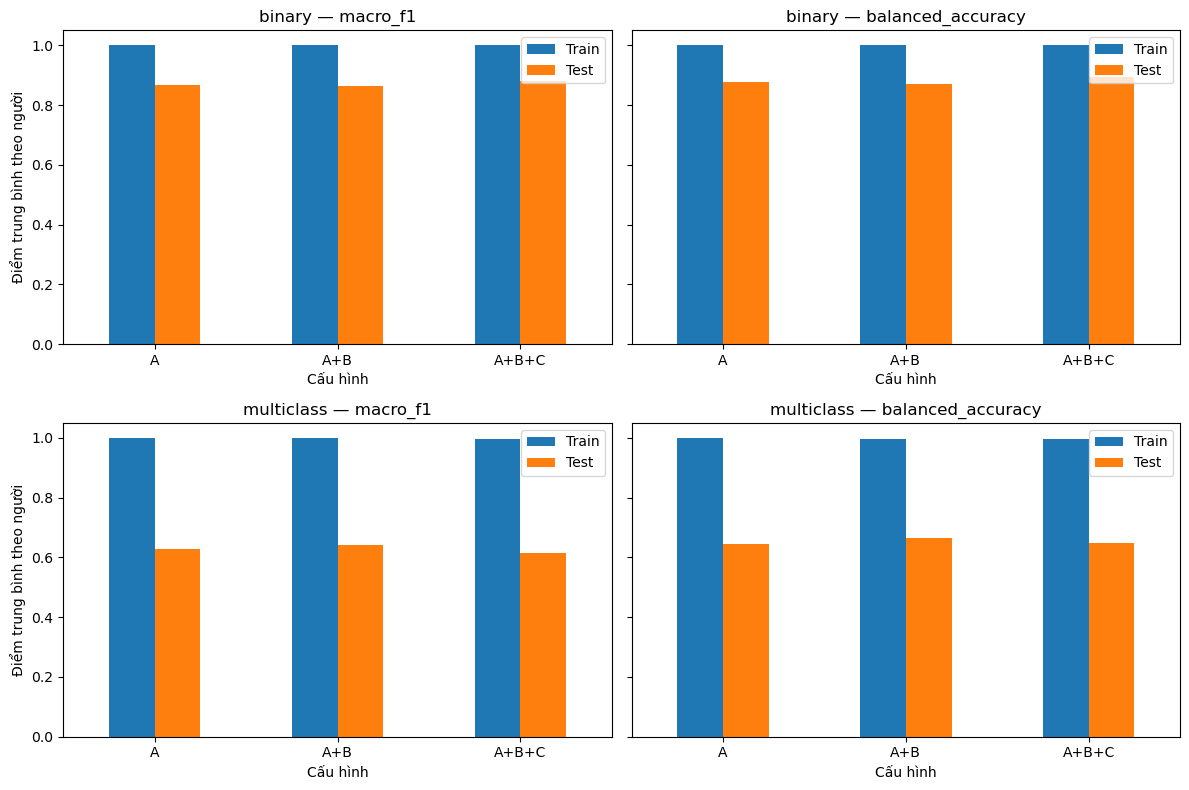

### Nhận xét điểm train–test
- multiclass, A: train Macro-F1 1.0000, test Macro-F1 0.6278, chênh lệch +0.3722.
- multiclass, A+B: train Macro-F1 0.9977, test Macro-F1 0.6414, chênh lệch +0.3563.
- multiclass, A+B+C: train Macro-F1 0.9969, test Macro-F1 0.6147, chênh lệch +0.3822.
- binary, A: train Macro-F1 1.0000, test Macro-F1 0.8678, chênh lệch +0.1322.
- binary, A+B: train Macro-F1 0.9999, test Macro-F1 0.8624, chênh lệch +0.1375.
- binary, A+B+C: train Macro-F1 0.9997, test Macro-F1 0.8813, chênh lệch +0.1184.
- binary, A+B so với A: thay đổi test Macro-F1 -0.0054, Balanced Accuracy -0.0045.
- binary, A+B+C so với A: thay đổi test Macro-F1 +0.0134, Balanced Accuracy +0.0177.
- multiclass, A+B so với A: thay đổi test Macro-F1 +0.0136, Balanced Accuracy +0.0196.
- multiclass, A+B+C so với A: thay đổi test Macro-F1 -0.0131, Balanced Accuracy +0.0032.

Điểm train cao hơn test cho thấy mô hình khớp dữ liệu đã học tốt hơn dữ liệu của người giữ riêng. Chênh lệch lớn gợi ý cần xem xét overfitting và khác biệt giữa người. Việc thêm cấu hình được đánh giá qua cả điểm test và chênh lệch train–test. Kết quả này mô tả ba cấu hình đã định trước; quy trình chọn tham số bằng inner CV thuộc EXP-009.

In [8]:
import matplotlib.pyplot as plt

verification_path = supplement_output / "verification.json"
if not verification_path.exists():
    print("Chưa có kết quả train–test cho ba cấu hình.")
else:
    check = json.loads(verification_path.read_text(encoding="utf-8"))
    assert check["status"] == "passed" and check["scope"] == "main"
    assert check["n_folds"] == 90 and check["n_test_subjects"] == 15
    train_test = pd.read_csv(supplement_output / "metrics.csv")
    order = ["A", "A+B", "A+B+C"]
    assert len(train_test) == 90
    assert not train_test.duplicated(["task", "subject_id", "stage"]).any()
    assert set(train_test["stage"]) == set(order)
    assert set(train_test["task"]) == {"binary", "multiclass"}
    assert all(
        set(rows["subject_id"]) == set(supplement_settings["expected_subjects"])
        for _, rows in train_test.groupby(["task", "stage"])
    )
    for metric in ["macro_f1", "balanced_accuracy"]:
        train_test[f"gap_{metric}"] = train_test[f"train_{metric}"] - train_test[f"test_{metric}"]
    score_columns = [
        f"{split}_{metric}" for metric in ["macro_f1", "balanced_accuracy"]
        for split in ["train", "test", "gap"]
    ]
    display(train_test.groupby(["task", "stage"])[score_columns].agg(["mean", "std"]).round(4))
    train_test.to_csv(experiment / "results_train_test.csv", index=False)

    figures = experiment / "figures"
    figures.mkdir(exist_ok=True)
    fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharey=True)
    for row, task in enumerate(["binary", "multiclass"]):
        means = train_test.loc[train_test["task"].eq(task)].groupby("stage").mean(numeric_only=True).loc[order]
        for col, metric in enumerate(["macro_f1", "balanced_accuracy"]):
            means[[f"train_{metric}", f"test_{metric}"]].rename(
                columns={f"train_{metric}": "Train", f"test_{metric}": "Test"}
            ).plot.bar(ax=axes[row, col], rot=0, title=f"{task} — {metric}")
            axes[row, col].set_ylim(0, 1.05)
            axes[row, col].set_xlabel("Cấu hình")
            axes[row, col].set_ylabel("Điểm trung bình theo người")
    fig.tight_layout()
    fig.savefig(figures / "rf_cumulative_train_test.png", dpi=150)
    plt.show()

    from IPython.display import Markdown
    paragraphs = ["### Nhận xét điểm train–test"]
    for (task, stage), rows in train_test.groupby(["task", "stage"], sort=False):
        paragraphs.append(
            f"- {task}, {stage}: train Macro-F1 {rows.train_macro_f1.mean():.4f}, "
            f"test Macro-F1 {rows.test_macro_f1.mean():.4f}, "
            f"chênh lệch {rows.gap_macro_f1.mean():+.4f}."
        )
    for task in ["binary", "multiclass"]:
        means = train_test.loc[train_test["task"].eq(task)].groupby("stage").mean(numeric_only=True)
        for stage in order[1:]:
            delta_f1 = means.loc[stage, "test_macro_f1"] - means.loc["A", "test_macro_f1"]
            delta_ba = means.loc[stage, "test_balanced_accuracy"] - means.loc["A", "test_balanced_accuracy"]
            paragraphs.append(
                f"- {task}, {stage} so với A: thay đổi test Macro-F1 {delta_f1:+.4f}, "
                f"Balanced Accuracy {delta_ba:+.4f}."
            )
    paragraphs.append(
        "\nĐiểm train cao hơn test cho thấy mô hình khớp dữ liệu đã học tốt hơn dữ liệu của người giữ riêng. "
        "Chênh lệch lớn gợi ý cần xem xét overfitting và khác biệt giữa người. "
        "Việc thêm cấu hình được đánh giá qua cả điểm test và chênh lệch train–test. "
        "Kết quả này mô tả ba cấu hình đã định trước; quy trình chọn tham số bằng inner CV thuộc EXP-009."
    )
    display(Markdown("\n".join(paragraphs)))


## Lần 4 — So sánh ba cấu hình RF với 100 cây - 22/11/2026  
Mục tiêu: xem kết quả thay đổi thế nào khi dùng 100 cây thay cho 20 cây ở lần 3. Cả ba cấu hình đều dùng 100 cây; B và C vẫn giữ ý nghĩa như lần 3.

| Cấu hình | Số cây | Độ sâu tối đa | Số đặc trưng xét tại mỗi lần chia nhánh |
| --- | --- | --- | --- |
| A | 100 | Không giới hạn | `sqrt` (căn bậc hai số đặc trưng) |
| A+B | 100 | 8 | `sqrt` |
| A+B+C | 100 | 8 | 25% số đặc trưng |

Giữ nguyên dữ liệu, 68 đặc trưng, seed 42, cách xử lý giá trị thiếu và LOSO: mỗi fold học từ 14 người, kiểm tra trên 1 người còn lại. Với 15 người, 2 bài toán và 3 cấu hình, một lượt đầy đủ có **90 fold mô hình**. Điểm train tính trên dữ liệu đã học; điểm test tính trên người giữ riêng.

Đây là so sánh các cấu hình định trước, chưa phải quy trình chọn tham số bằng inner CV. `max_features` điều khiển số đặc trưng được xét ở mỗi lần chia nhánh, không thay đổi bảng dữ liệu 68 đặc trưng.


In [9]:
from pathlib import Path
import subprocess
import json
import pandas as pd
import yaml

here100 = Path.cwd()
repo100 = next(p for p in (here100, *here100.parents) if (p / 'scripts/run_rf_train_test.py').is_file())
experiment100 = repo100 / 'experiments/02_tuning/EXP-009_RF'
config100_path = experiment100 / 'config_train_test_100.yaml'
settings100 = yaml.safe_load(config100_path.read_text(encoding='utf-8'))
output100 = repo100 / settings100['output_dir']
assert all(s['params']['n_estimators'] == 100 for s in settings100['stages'])

RUN_100_TREES = False

if RUN_100_TREES:
    subprocess.run([
        str(repo100 / '.venv-g1/Scripts/python.exe'), '-X', 'utf8',
        'scripts/run_rf_train_test.py', '--config', str(config100_path),
    ], cwd=repo100, check=True)
else:
    print('Chưa chạy huấn luyện. Đổi RUN_100_TREES = True để chạy lần 4.')

train_macro_f1         test_macro_f1         gap_macro_f1  \
                           mean     std          mean     std         mean   
task       stage                                                             
binary     A             1.0000  0.0000        0.8735  0.1440       0.1265   
           A+B           0.9999  0.0001        0.8749  0.1372       0.1250   
           A+B+C         0.9999  0.0001        0.8922  0.1366       0.1076   
multiclass A             1.0000  0.0000        0.6480  0.1297       0.3520   
           A+B           0.9986  0.0007        0.6320  0.1477       0.3666   
           A+B+C         0.9974  0.0020        0.6226  0.1430       0.3748   

                         train_balanced_accuracy          \
                     std                    mean     std   
task       stage                                           
binary     A      0.1440                  1.0000  0.0000   
           A+B    0.1372                  0.9999  0.0001   
           A+B+C  0.1366                  0.9999  0.0002   
multiclass A      0.1297                  1.0000  0.0000   
           A+B    0.1475                  0.9979  0.0010   
           A+B+C  0.1421                  0.9961  0.0031   

                 test_balanced_accuracy         gap_balanced_accuracy          
                                   mean     std                  mean     std  
task       stage                                                               
binary     A                     0.8865  0.1143                0.1135  0.1143  
           A+B                   0.8864  0.1035                0.1136  0.1036  
           A+B+C                 0.9007  0.1128                0.0992  0.1129  
multiclass A                     0.6700  0.1204                0.3300  0.1204  
           A+B                   0.6561  0.1412                0.3418  0.1407  
           A+B+C                 0.6398  0.1476                0.3563  0.1460

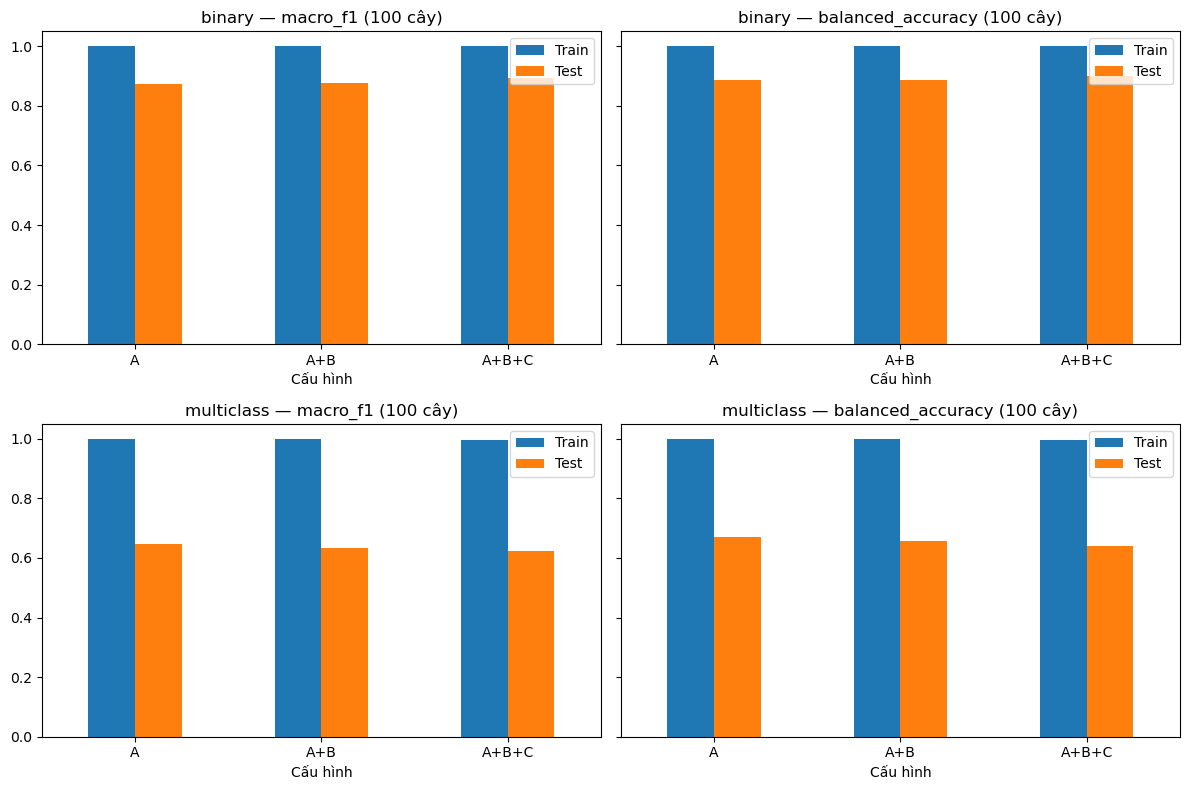

### Nhận xét lần 4: RF 100 cây
- binary, A+B so với A: test Macro-F1 thay đổi +0.0014; Balanced Accuracy -0.0001.
- binary, A+B+C so với A+B: test Macro-F1 thay đổi +0.0173; Balanced Accuracy +0.0143.
- multiclass, A+B so với A: test Macro-F1 thay đổi -0.0159; Balanced Accuracy -0.0139.
- multiclass, A+B+C so với A+B: test Macro-F1 thay đổi -0.0094; Balanced Accuracy -0.0164.
Đọc cả điểm test và khoảng cách train–test; tăng số cây không bảo đảm điểm test tăng. Các chênh lệch trên là kết quả mô tả, chưa phải kiểm định ý nghĩa thống kê.

In [10]:

verification100_path = output100 / 'verification.json'
if not verification100_path.exists():
    print('Chưa có kết quả lần 4. Chạy ô huấn luyện với RUN_100_TREES = True trước.')
else:
    from IPython.display import Markdown, display
    import matplotlib.pyplot as plt
    check100 = json.loads(verification100_path.read_text(encoding='utf-8'))
    assert check100['status'] == 'passed' and check100['scope'] == 'main'
    assert check100['n_folds'] == 90 and check100['n_test_subjects'] == 15
    scores100 = pd.read_csv(output100 / 'metrics.csv')
    order100 = ['A', 'A+B', 'A+B+C']
    assert len(scores100) == 90
    assert not scores100.duplicated(['task', 'subject_id', 'stage']).any()
    assert set(scores100.stage) == set(order100)
    assert set(scores100.task) == {'binary', 'multiclass'}
    assert all(set(rows.subject_id) == set(settings100['expected_subjects'])
               for _, rows in scores100.groupby(['task', 'stage']))
    metrics100 = ['macro_f1', 'balanced_accuracy']
    for metric in metrics100:
        scores100[f'gap_{metric}'] = scores100[f'train_{metric}'] - scores100[f'test_{metric}']
    columns100 = [f'{split}_{metric}' for metric in metrics100 for split in ['train', 'test', 'gap']]
    assert scores100[columns100].notna().all().all()
    display(scores100.groupby(['task', 'stage'])[columns100].agg(['mean', 'std']).round(4))
    scores100.to_csv(experiment100 / 'results_train_test_100.csv', index=False)

    fig100, axes100 = plt.subplots(2, 2, figsize=(12, 8), sharey=True)
    comments100 = ['### Nhận xét lần 4: RF 100 cây']
    for row, task in enumerate(['binary', 'multiclass']):
        means100 = scores100.loc[scores100.task.eq(task)].groupby('stage')[columns100].mean().loc[order100]
        for col, metric in enumerate(metrics100):
            means100[[f'train_{metric}', f'test_{metric}']].rename(
                columns={f'train_{metric}': 'Train', f'test_{metric}': 'Test'}
            ).plot.bar(ax=axes100[row, col], rot=0, title=f'{task} — {metric} (100 cây)')
            axes100[row, col].set_ylim(0, 1.05)
            axes100[row, col].set_xlabel('Cấu hình')
        for previous, current in zip(order100, order100[1:]):
            delta100 = means100.loc[current] - means100.loc[previous]
            comments100.append(
                f'- {task}, {current} so với {previous}: test Macro-F1 thay đổi '
                f'{delta100.test_macro_f1:+.4f}; Balanced Accuracy '
                f'{delta100.test_balanced_accuracy:+.4f}.'
            )
    fig100.tight_layout()
    (experiment100 / 'figures').mkdir(exist_ok=True)
    fig100.savefig(experiment100 / 'figures/rf_cumulative_train_test_100.png', dpi=150)
    plt.show()
    comments100.append('Đọc cả điểm test và khoảng cách train–test; tăng số cây không bảo đảm điểm test tăng. Các chênh lệch trên là kết quả mô tả, chưa phải kiểm định ý nghĩa thống kê.')
    display(Markdown('\n'.join(comments100)))